# 3r_migration_kumamoto: in- and out-migration by age around the 2016 Kumamoto Earthquake, by cohort

The 45 municipalities listed under 熊本 in `dt/analysis_original_data.xlsx` (sheet `1_市町村一覧`). The notebook has three parts:

1. **Single-year ages with `ungroup`** (figures 1–2). Population and migrants are published in 5-year bands. `ungroup::pclm()` (penalized composite link model; Rizzi et al. 2015) splits each municipality-year into single years of age 0–104, and keeps every band's total. Figures 1–2 show what that looks like for a large, a medium and a small municipality.
2. **5-year profiles before, during and after the earthquake** (figure 3). These are the published bands, with no ungrouping: in-, out- and net-migration rates per 1,000 residents of the same age band.
3. **Cohort movement rates** (figures 4–7).
   - **Cohorts:** the 5-year age groups on the last count before the earthquake (2016-01-01), followed year by year as they age.
   - **Rate:** in each year *t*, the cohort's movers ÷ the cohort's own population on 1 January *t*, per 1,000. Each year is computed on its own.
   - **Back-cast:** 2014–2015 trace the same cohorts back for a pre-quake reference.
4. **Change from the pre-quake baseline** (figures 8–10). The net rate of each published 5-year age band in each year, minus the same band's 2014–15 reference (the mean of its 2014 and 2015 rates): by group (figure 8, and as line plots in figure 10) and per municipality for ages 25–29, 40–44 and 60–64 (figure 9).

**Data**
- **Migrants:** `dt/idou_age_sex_5yr_long.qs2`, built by `src/build_idou_age.R` from 住民基本台帳人口移動報告 (総務省統計局; e-Stat 00200523).
  - 転入 = in-migrants from other municipalities; 転出 = out-migrants to other municipalities. Moves within a municipality, births and deaths are not included.
  - **Japanese movers (日本人移動者) only.** The 2014–2017 tables publish no other basis.
  - Municipal 5-year age × sex detail exists only from 2014 (see `doc/data.md`).
  - Years used: 2014–2025, calendar years.
- **Population:** `dt/jumin_age_sex_5yr_long.qs2` (住民基本台帳), Japanese residents (`basis == "japanese"`) to match the movers. Counts on 1 January of each year, both sexes.
  - The top band is 80+ in 2014 and 100+ from 2015.

**Approximations** (see `doc/caution.md`)
- **Lexis.** Movers in year *t* reported at age *x* are split evenly between the cohorts aged *x* and *x*−1 on 1 January *t*. In other words, the cohort aged *x* on 1 January gets ½·(M<sub>x</sub> + M<sub>x+1</sub>). This assumes the reported age is age at the move and that moves are spread evenly over the year.
- **ungroup uncertainty.** Fits for small municipalities and for migrant counts are smooth guesses. The band totals are exact, but the shape within a band is not.

Figures are also written to `res/` as `3r_<NN>_<item>.png` via `show_save()`. Tables are shown here only. The pclm fits are cached in `output/3r_pclm_cache.qs2`; delete it to refit (a few minutes).

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

# The notebook lives in src/; resolve the repo root so paths work from either.
root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"   # conda font-ttf-noto-cjk (pinned in the Dockerfile)

nb_prefix <- "3r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}

years <- 2014:2025      # calendar years of migration; population on 1 January
base_year <- 2016       # 2016-01-01: last count before the 2016-04-14/16 earthquake
event_x <- 2016         # the quake falls inside calendar year 2016
top_age <- 105          # single years 0..104; open bands are spread up to here

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Migrants: 住民基本台帳人口移動報告 (Statistics Bureau, e-Stat), Japanese movers between municipalities. ",
                   "Population: Basic Resident Register, Japanese residents, 1 January.")

In [2]:
# Study municipalities and the high-damage group (全壊率 >= 1)
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 == "熊本") |>
  transmute(code = 市町村コード, muni = 市町村, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`)) |>
  mutate(group = case_when(zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
                           code == "43100" ~ "熊本市",
                           TRUE ~ "Other listed municipalities"))
group_levels <- c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed municipalities")
group_cols <- setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels)

pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計", year %in% years) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, year, age_band, n = pop)

mig5 <- qs_read(file.path(root, "dt/idou_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, level == "municipality", mover == "japanese", sex == "計",
         year %in% years, age_band != "origin_unknown") |>
  mutate(age_band = as.character(age_band)) |>
  select(code, year, direction, age_band, n)

# Coverage: every municipality has population and both directions in every year
bind_rows(pop5 |> mutate(series = "population"),
          mig5 |> mutate(series = direction)) |>
  filter(age_band == "total") |>
  group_by(series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            code_years = n(), missing = sum(is.na(n)), total = sum(n), .groups = "drop") |>
  as.data.frame()
study |> count(group) |> as.data.frame()

series,municipalities,years,code_years,missing,total
<chr>,<int>,<chr>,<int>,<int>,<dbl>
in,45,2014–2025,540,0,834104
out,45,2014–2025,540,0,869676
population,45,2014–2025,540,0,21084287


group,n
<chr>,<int>
High damage (全壊率 ≥ 1),5
Other listed municipalities,39
熊本市,1


## 1. From 5-year bands to single years with `ungroup`

`pclm(x, y, nlast)` takes the lower bound of each band (`x`), the counts (`y`) and the width of the open last band (`nlast`). It returns a smooth single-year distribution whose sums over each band equal the input counts. The smoothing parameter λ is chosen by BIC for each fit.

- **Open bands:** population's open top band is spread over 100–104 (80–104 in 2014) and migrants' 90+ over 90–104.
- **Below:** the 2016-01-01 population and the 2016 movers for three municipalities of very different size. Bars are the published bands drawn as counts per single year (band count ÷ band width); the line is the pclm fit with its 95% interval.
- **Smoothing (λ in the table):** λ grows as counts shrink. For 五木村 (~1,200 residents, ~40 movers) it reaches pclm's upper search bound (≈1e5), so the fit is close to the smoothest curve that still matches the band totals. Its within-band shape carries almost no information.

In [3]:
# Band label -> lower bound ("0_4" -> 0, "80+" -> 80). Drops the total and, when
# the finer 80-84 ... 100+ bands are present, the harmonised 80+.
band_table <- function(bands, counts) {
  keep <- bands != "total"
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower) |>
    mutate(upper = lead(lower, default = top_age))   # bands are contiguous; open band ends at top_age
}

# Single-year ages 0..top_age-1 from one set of bands
ungroup_bands <- function(bands, counts) {
  b <- band_table(bands, counts)
  if (sum(b$n) == 0) {
    return(tibble(age = 0:(top_age - 1), fit = 0, lo = 0, hi = 0, lambda = NA_real_))
  }
  # pclm advises against zero counts (sparse migrant bands in small villages);
  # replace them with a negligible 1e-4 as the package's message suggests.
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower), verbose = FALSE)
  tibble(age = 0:(top_age - 1), fit = unname(fitted(m)),
         lo = unname(m$ci$lower), hi = unname(m$ci$upper),
         lambda = unname(m$smoothPar["lambda"]))
}

In [4]:
showcase <- study |> filter(short %in% c("熊本市", "益城町", "五木村")) |>
  mutate(short = factor(short, levels = c("熊本市", "益城町", "五木村")))

demo <- function(src, yr) {
  src |>
    filter(code %in% showcase$code, year == yr) |>
    group_by(across(any_of(c("code", "direction")))) |>
    group_modify(function(g, key) {
      bars <- band_table(g$age_band, g$n)
      fit <- ungroup_bands(g$age_band, g$n)
      bind_rows(bars |> mutate(kind = "bars"), fit |> mutate(kind = "fit"))
    }) |>
    ungroup() |>
    left_join(showcase |> select(code, short), by = "code")
}
demo_pop <- demo(pop5, base_year)
demo_mig <- demo(mig5, base_year)

# Check: single-year fits add back to the published band totals
bind_rows(demo_pop |> mutate(direction = "population"), demo_mig) |>
  group_by(short, direction) |>
  summarise(band_total = sum(n[kind == "bars"]), fit_total = round(sum(fit[kind == "fit"]), 1),
            lambda = round(first(na.omit(lambda)), 1), .groups = "drop") |>
  as.data.frame()

short,direction,band_total,fit_total,lambda
<fct>,<chr>,<dbl>,<dbl>,<dbl>
熊本市,in,41711,41711,1149.6
熊本市,out,43251,43251,1674.7
熊本市,population,730589,730589,0.3
益城町,in,1165,1165,10183.0
益城町,out,2484,2484,12451.7
益城町,population,34503,34503,8944.5
五木村,in,41,41,99999.6
五木村,out,46,46,99999.6
五木村,population,1186,1186,99999.6


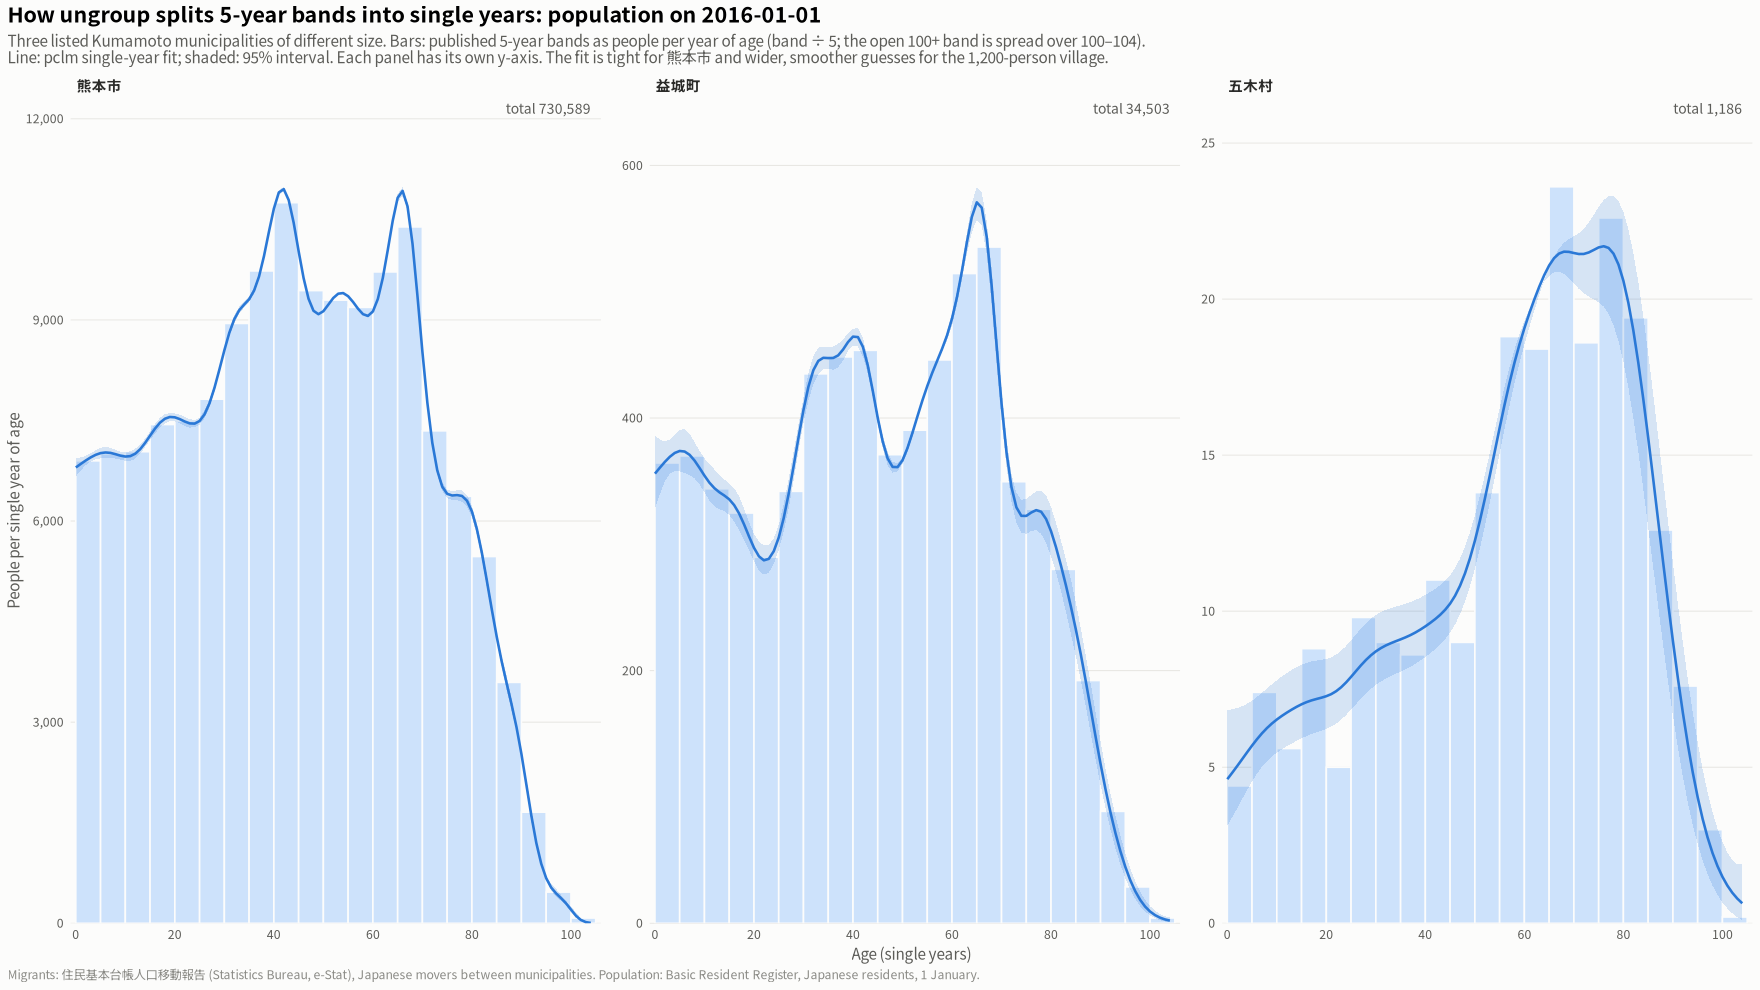

In [5]:
plot_demo <- function(dd, facet, title, subtitle, ylab) {
  bars <- dd |> filter(kind == "bars") |> mutate(per_year = n / (upper - lower))
  fit <- dd |> filter(kind == "fit")
  lab <- bars |> group_by(across(all_of(facet))) |> summarise(total = sum(n), .groups = "drop")
  ggplot() +
    geom_rect(data = bars, aes(xmin = lower, xmax = upper, ymin = 0, ymax = per_year),
              fill = "#cde2fb", colour = surface, linewidth = 0.5) +
    geom_ribbon(data = fit, aes(age, ymin = lo, ymax = hi), fill = "#2a78d6", alpha = 0.18) +
    geom_line(data = fit, aes(age, fit), colour = "#2a78d6", linewidth = 0.8) +
    geom_text(data = lab, aes(x = 104, y = Inf, label = paste0("total ", scales::comma(total))),
              hjust = 1, vjust = 1.4, size = 3.2, colour = ink2, family = jp_font) +
    scale_x_continuous(breaks = seq(0, 100, 20), expand = expansion(mult = 0.01)) +
    scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.12))) +
    labs(title = title, subtitle = subtitle, x = "Age (single years)", y = ylab, caption = src_note) +
    base_theme()
}

show_save(
  plot_demo(demo_pop, "short",
            "How ungroup splits 5-year bands into single years: population on 2016-01-01",
            paste0("Three listed Kumamoto municipalities of different size. Bars: published 5-year bands as people per year of age ",
                   "(band ÷ 5; the open 100+ band is spread over 100–104).\nLine: pclm single-year fit; shaded: 95% interval. ",
                   "Each panel has its own y-axis. The fit is tight for 熊本市 and wider, smoother guesses for the 1,200-person village."),
            "People per single year of age") +
    facet_wrap(~short, ncol = 3, scales = "free_y"),
  "01_ungroup_population", width = 16, height = 6)

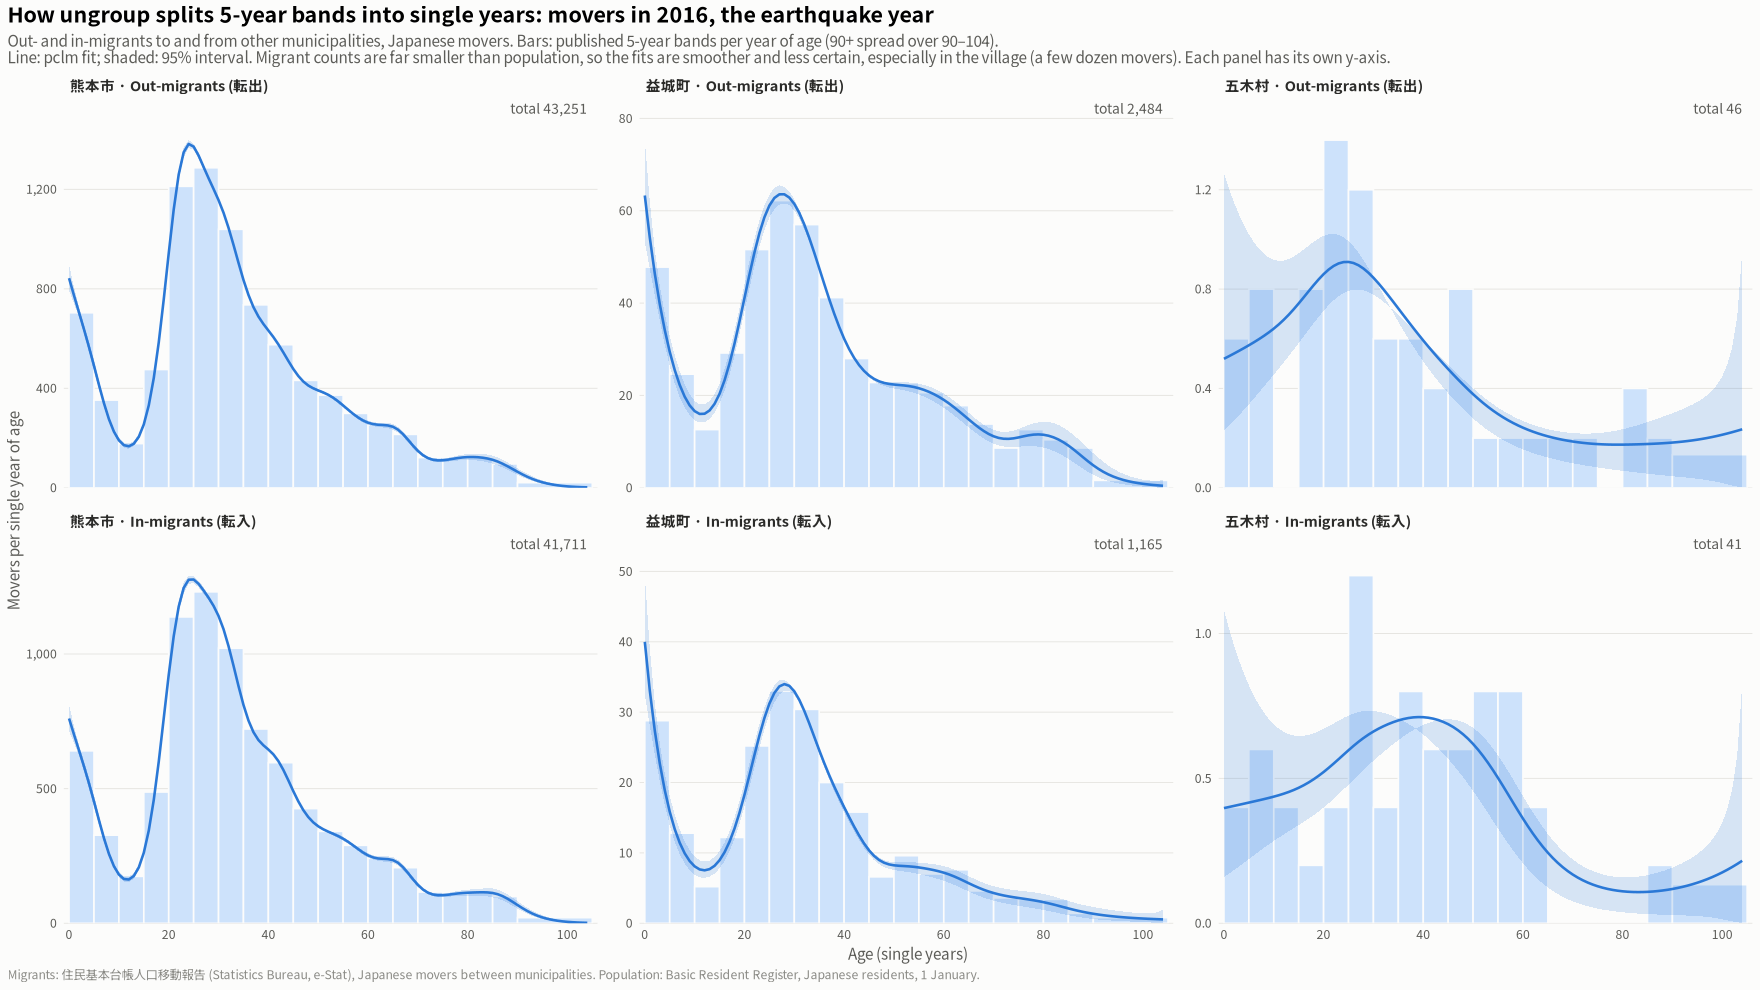

In [6]:
demo_mig2 <- demo_mig |>
  mutate(direction = ifelse(direction == "out", "Out-migrants (転出)", "In-migrants (転入)"),
         panel = factor(paste0(short, " · ", direction),
                        levels = paste0(rep(levels(showcase$short), 2), " · ",
                                        rep(c("Out-migrants (転出)", "In-migrants (転入)"), each = 3))))
show_save(
  plot_demo(demo_mig2, "panel",
            "How ungroup splits 5-year bands into single years: movers in 2016, the earthquake year",
            paste0("Out- and in-migrants to and from other municipalities, Japanese movers. Bars: published 5-year bands per year of age ",
                   "(90+ spread over 90–104).\nLine: pclm fit; shaded: 95% interval. Migrant counts are far smaller than population, ",
                   "so the fits are smoother and less certain, especially in the village (a few dozen movers). Each panel has its own y-axis."),
            "Movers per single year of age") +
    facet_wrap(~panel, ncol = 3, scales = "free_y"),
  "02_ungroup_migration", width = 16, height = 8.5)

## 2. Fitting every municipality and year

One fit per municipality × year × series (population, 転入, 転出), 2014–2025: 45 × 12 × 3 = 1,620 fits. The fits are cached. The check below compares each fit's sum with the published total: population fits are exact, and migrant fits are within about 2 movers, because pclm's Poisson fit of very sparse bands does not reproduce them exactly.

In [7]:
cache <- file.path(root, "output/3r_pclm_cache.qs2")
if (file.exists(cache)) {
  fits <- qs_read(cache)
} else {
  dir.create(dirname(cache), showWarnings = FALSE, recursive = TRUE)
  inputs <- bind_rows(pop5 |> mutate(series = "pop"),
                      mig5 |> rename(series = direction))
  t0 <- Sys.time()
  fits <- inputs |>
    group_by(code, year, series) |>
    group_modify(function(g, key) ungroup_bands(g$age_band, g$n)) |>
    ungroup()
  message("pclm fits: ", n_distinct(paste(fits$code, fits$year, fits$series)),
          " in ", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(fits, cache)
}

# Check: single-year sums vs the published totals
bind_rows(pop5 |> mutate(series = "pop"), mig5 |> rename(series = direction)) |>
  filter(age_band == "total") |>
  left_join(fits |> group_by(code, year, series) |> summarise(fit_total = sum(fit), .groups = "drop"),
            by = c("code", "year", "series")) |>
  group_by(series) |>
  summarise(fits = n(), max_abs_diff = round(max(abs(fit_total - n)), 2),
            published = sum(n), fitted = round(sum(fit_total)), .groups = "drop") |>
  as.data.frame()

series,fits,max_abs_diff,published,fitted
<chr>,<int>,<dbl>,<dbl>,<dbl>
in,540,2.27,834104,834112
out,540,1.20,869676,869680
pop,540,0.00,21084287,21084287


## 3. 5-year profiles of in- and out-migration, 熊本県, before / during / after

The published 5-year bands, without ungrouping. For each age band and period:
- **out-rate** = out-migrants ÷ population of the same band on 1 January, per 1,000 per year;
- **in-rate** is the same with in-migrants; **net** = in − out.

Each period's rate is the sum of movers ÷ the sum of 1 January populations over its years, i.e. a person-year-weighted mean.

- **Periods:** before 2014–15; the quake year 2016; after 2017–19; later 2020–25.
- **Groups:** the high-damage municipalities pooled, 熊本市, and the other 39 listed municipalities pooled.
- **Bands:** 80+ is the top band, since the 2014 population stops there.

In [8]:
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90+", "90_94", "95_99", "100+", "80+"), "80+", b)
bands5 <- c(paste0(seq(0, 75, 5), "_", seq(4, 79, 5)), "80+")
periods <- c("Before (2014–15)", "Quake year (2016)", "After (2017–19)", "Later (2020–25)")
period_of <- function(y) factor(case_when(y <= 2015 ~ periods[1], y == 2016 ~ periods[2],
                                          y <= 2019 ~ periods[3], TRUE ~ periods[4]), levels = periods)
period_cols <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods)

p5 <- pop5 |>
  filter(age_band != "total", !(age_band == "80+" & year >= 2015)) |>   # 80+ only where it is the top band
  mutate(band = to80(age_band)) |>
  group_by(code, year, band) |> summarise(pop = sum(n), .groups = "drop")
m5 <- mig5 |>
  filter(age_band != "total") |>
  mutate(band = to80(age_band)) |>
  group_by(code, year, band, direction) |> summarise(n = sum(n), .groups = "drop") |>
  pivot_wider(names_from = direction, values_from = n)
r5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  left_join(study |> select(code, group), by = "code") |>
  mutate(period = period_of(year)) |>
  group_by(group, period, band) |>
  summarise(pop = sum(pop), out = sum(out), `in` = sum(`in`), .groups = "drop") |>
  mutate(`Out-migration` = 1000 * out / pop, `In-migration` = 1000 * `in` / pop,
         `Net (in − out)` = `Out-migration` * -1 + `In-migration`) |>
  pivot_longer(c(`Out-migration`, `In-migration`, `Net (in − out)`), names_to = "measure", values_to = "rate") |>
  mutate(measure = factor(measure, levels = c("Out-migration", "In-migration", "Net (in − out)")),
         group = factor(group, levels = group_levels),
         band = factor(band, levels = bands5))

# Table: rates per 1,000 for the young adult bands, high-damage group
r5 |>
  filter(group == group_levels[1], band %in% c("15_19", "20_24", "25_29", "30_34", "35_39")) |>
  mutate(rate = round(rate, 1)) |>
  select(measure, band, period, rate) |>
  pivot_wider(names_from = period, values_from = rate) |>
  arrange(measure, band) |>
  as.data.frame()

measure,band,Before (2014–15),Quake year (2016),After (2017–19),Later (2020–25)
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Out-migration,15_19,59.3,86.9,69.0,58.5
Out-migration,20_24,134.8,199.5,159.0,160.8
Out-migration,25_29,122.8,160.3,141.4,143.3
Out-migration,30_34,79.7,121.5,89.5,79.4
Out-migration,35_39,52.9,84.2,54.7,45.3
In-migration,15_19,47.7,42.2,40.6,40.4
In-migration,20_24,102.4,83.0,116.0,135.3
In-migration,25_29,141.1,97.3,134.0,179.4
In-migration,30_34,99.7,71.7,96.0,114.4


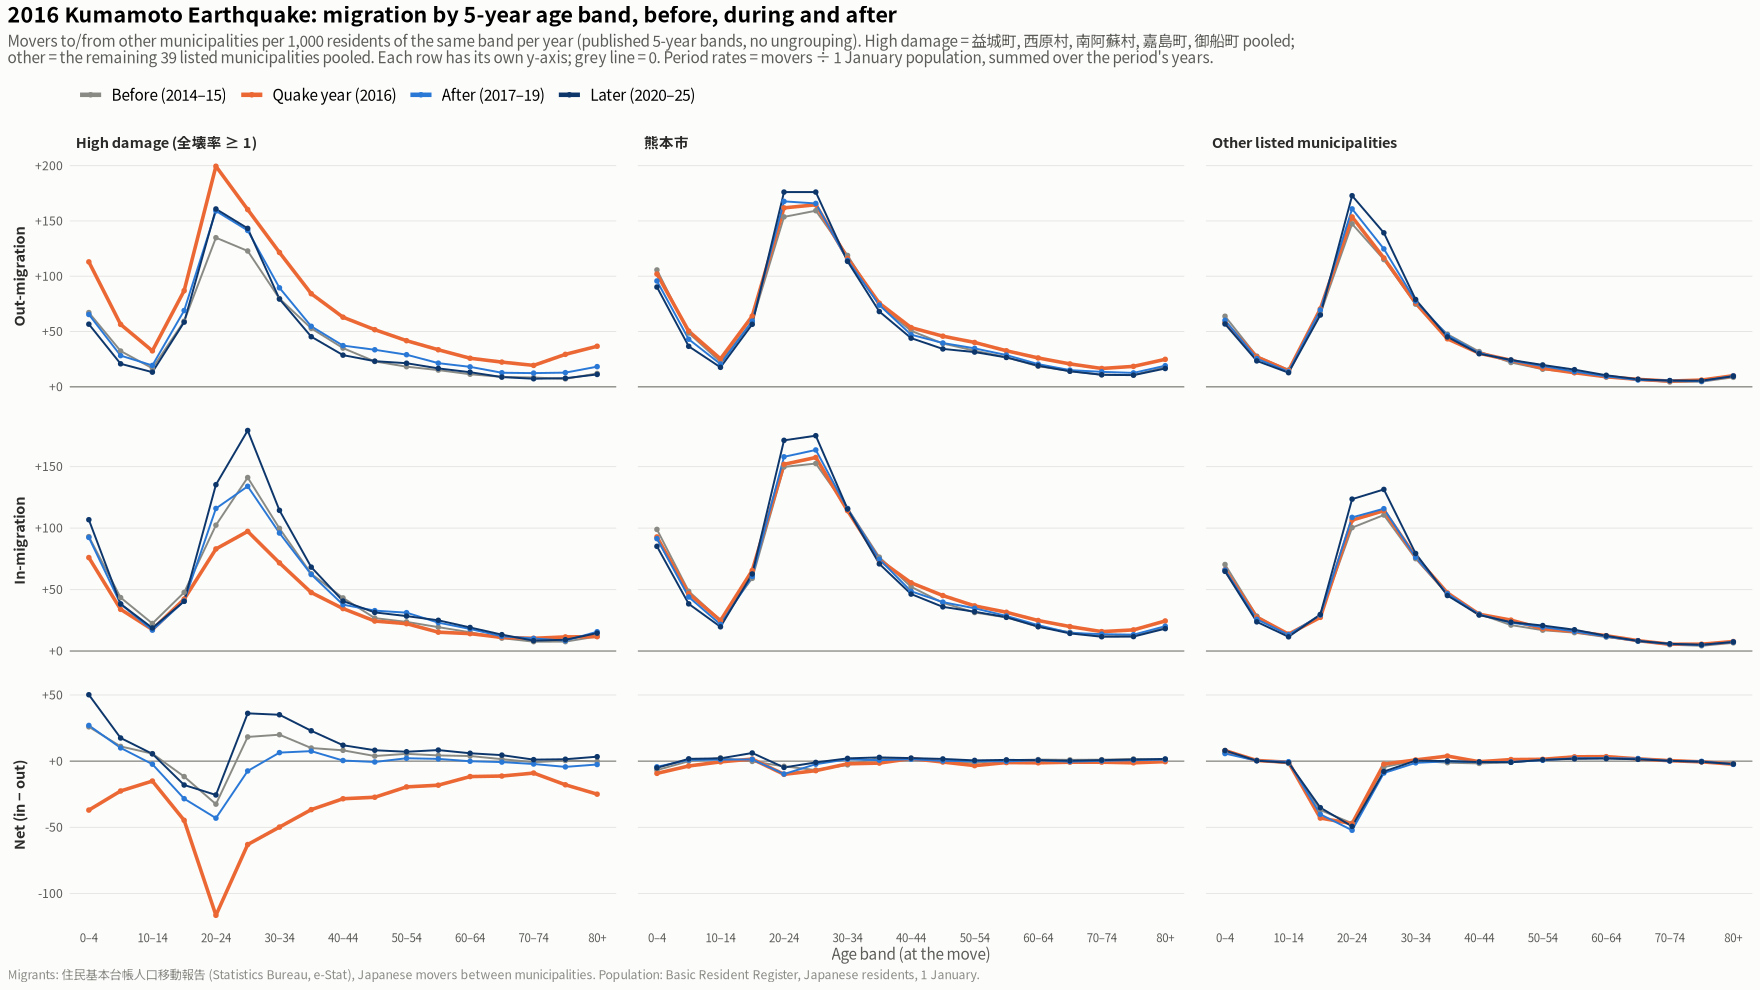

In [9]:
band_labels <- sub("_", "–", bands5)
p3 <- ggplot(r5, aes(band, rate, colour = period, group = period)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(aes(linewidth = period == periods[2])) +
  geom_point(size = 1.1) +
  facet_grid(measure ~ group, scales = "free_y", switch = "y") +
  scale_colour_manual(values = period_cols, name = NULL) +
  scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
  scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, sub("_", "–", b), "")) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: migration by 5-year age band, before, during and after",
       subtitle = paste0("Movers to/from other municipalities per 1,000 residents of the same band per year (published 5-year bands, no ungrouping). ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled;\nother = the remaining 39 listed municipalities pooled. ",
                         "Each row has its own y-axis; grey line = 0. Period rates = movers ÷ 1 January population, summed over the period's years."),
       x = "Age band (at the move)", y = NULL, caption = src_note) +
  base_theme() +
  theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 90, hjust = 0.5),
        axis.text.x = element_text(size = 7.5)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p3, "03_kumamoto_inout_5yr", width = 16, height = 10)

## 4. Cohort movement rates, following the 2016-01-01 age groups

From the single-year fits:

- **Population:** P(*x*, *t*) is the cohort aged *x* on 1 January of year *t*.
- **Movers:** the cohort aged *x* on 1 January *t* is credited with ½·(M(*x*, *t*) + M(*x*+1, *t*)), where M(*x*, *t*) is the movers in year *t* reported at age *x*.
- **Cohorts:** each is defined by its 5-year age group *a*…*a*+4 on 2016-01-01. In year *t* it is aged *a*+*k*…*a*+4+*k*, with *k* = *t* − 2016; 2014 and 2015 are the back-cast (*k* = −2, −1).
  - Back-cast ages below 0 (not yet born) are dropped, so the youngest cohort's 2014–15 values cover only its born members.
- **Rates:** out-rate(*t*) = Σ credited out-movers ÷ Σ P over the cohort's ages in year *t*, per 1,000; the same for in-rate. Net = in − out. **Each year uses its own 1 January denominator.**
- **Wider cohorts:** cohorts 40 and older are grouped into wider bins to keep the figure readable. The rates are pooled, i.e. movers and population are summed before dividing.

In [10]:
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–84")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 84 ~ "70–84", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}

P1 <- fits |> filter(series == "pop") |> select(code, year, age, P = fit)
M1 <- fits |> filter(series != "pop") |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  # cohort aged x on 1 January gets half of the movers reported at x and x+1
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |>
  ungroup() |>
  select(-M) |>
  pivot_wider(names_from = series, values_from = Mc)

coh1 <- P1 |>
  inner_join(M1, by = c("code", "year", "age")) |>
  mutate(a0 = age - (year - base_year), cohort = cohort_of(a0)) |>   # age on 2016-01-01
  filter(a0 >= 0, !is.na(cohort)) |>
  left_join(study |> select(code, short, group), by = "code")

cohort_rates <- function(dd, ...) {
  dd |>
    group_by(..., cohort, year) |>
    summarise(P = sum(P), out = sum(out), `in` = sum(`in`), .groups = "drop") |>
    mutate(`Out-migration` = 1000 * out / P, `In-migration` = 1000 * `in` / P,
           `Net (in − out)` = `In-migration` - `Out-migration`)
}
cr_group <- cohort_rates(coh1, group) |> mutate(group = factor(group, levels = group_levels))
cr_muni  <- cohort_rates(coh1, code, short)

# Table: high-damage group, net rate per 1,000 by cohort and year
cr_group |>
  filter(group == group_levels[1]) |>
  mutate(net = round(`Net (in − out)`, 1)) |>
  select(cohort, year, net) |>
  pivot_wider(names_from = year, values_from = net) |>
  as.data.frame()

cohort,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,22.4,29.9,-36.2,11.0,15.0,20.5,18.0,14.7,13.7,11.4,7.6,4.9
5–9,11.4,14.5,-19.2,0.8,0.3,3.8,3.9,0.4,1.5,0.4,-1.9,-8.3
10–14,5.0,5.7,-16.8,-10.7,-13.6,-10.5,-16.0,-18.9,-20.2,-21.0,-22.9,-26.7
15–19,0.4,-12.2,-51.4,-39.8,-39.9,-29.3,-31.3,-14.1,-7.3,6.2,-4.4,28.2
20–24,-14.1,-39.8,-112.0,-46.9,-31.2,-2.9,17.8,26.9,44.9,61.2,27.5,44.6
25–29,0.3,6.6,-66.7,-11.9,6.8,8.4,31.3,27.3,39.9,42.6,25.1,27.2
30–34,16.1,28.7,-47.0,3.9,9.8,5.6,20.7,17.1,17.6,19.6,12.8,15.6
35–39,12.3,12.1,-35.9,2.2,0.0,9.2,13.5,14.1,5.5,9.1,7.3,11.9
40–49,8.0,6.0,-26.8,-0.8,-2.0,5.5,8.4,7.8,6.0,8.4,8.1,10.3


In [11]:
# Table: high-damage group, out-rate per 1,000 by cohort and year
cr_group |>
  filter(group == group_levels[1]) |>
  mutate(out = round(`Out-migration`, 1)) |>
  select(cohort, year, out) |>
  pivot_wider(names_from = year, values_from = out) |>
  as.data.frame()

cohort,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,72.1,63.1,103.1,47.2,41.9,31.8,24.5,20.0,18.4,18.9,15.9,17.8
5–9,37.6,32.1,51.2,24.5,29.4,21.1,22.6,24.3,26.5,30.2,32.6,45.9
10–14,25.2,24.6,44.7,34.4,45.1,45.2,59.1,71.3,86.3,94.8,109.0,137.3
15–19,40.8,56.3,95.0,90.9,106.8,124.9,144.6,148.6,162.5,163.1,165.9,152.7
20–24,97.1,132.2,192.6,152.3,165.3,162.7,149.4,142.4,123.7,114.7,106.3,86.4
25–29,129.3,132.7,162.6,120.3,118.8,116.0,89.5,81.1,63.7,59.2,54.3,46.0
30–34,96.4,85.0,117.0,73.0,71.5,68.6,51.7,45.7,37.5,34.8,31.5,29.6
35–39,57.6,58.0,82.8,44.8,50.0,39.5,32.1,28.5,29.8,24.9,23.4,22.5
40–49,31.3,31.8,56.3,32.2,34.6,31.3,24.0,20.5,22.0,19.6,19.8,18.8


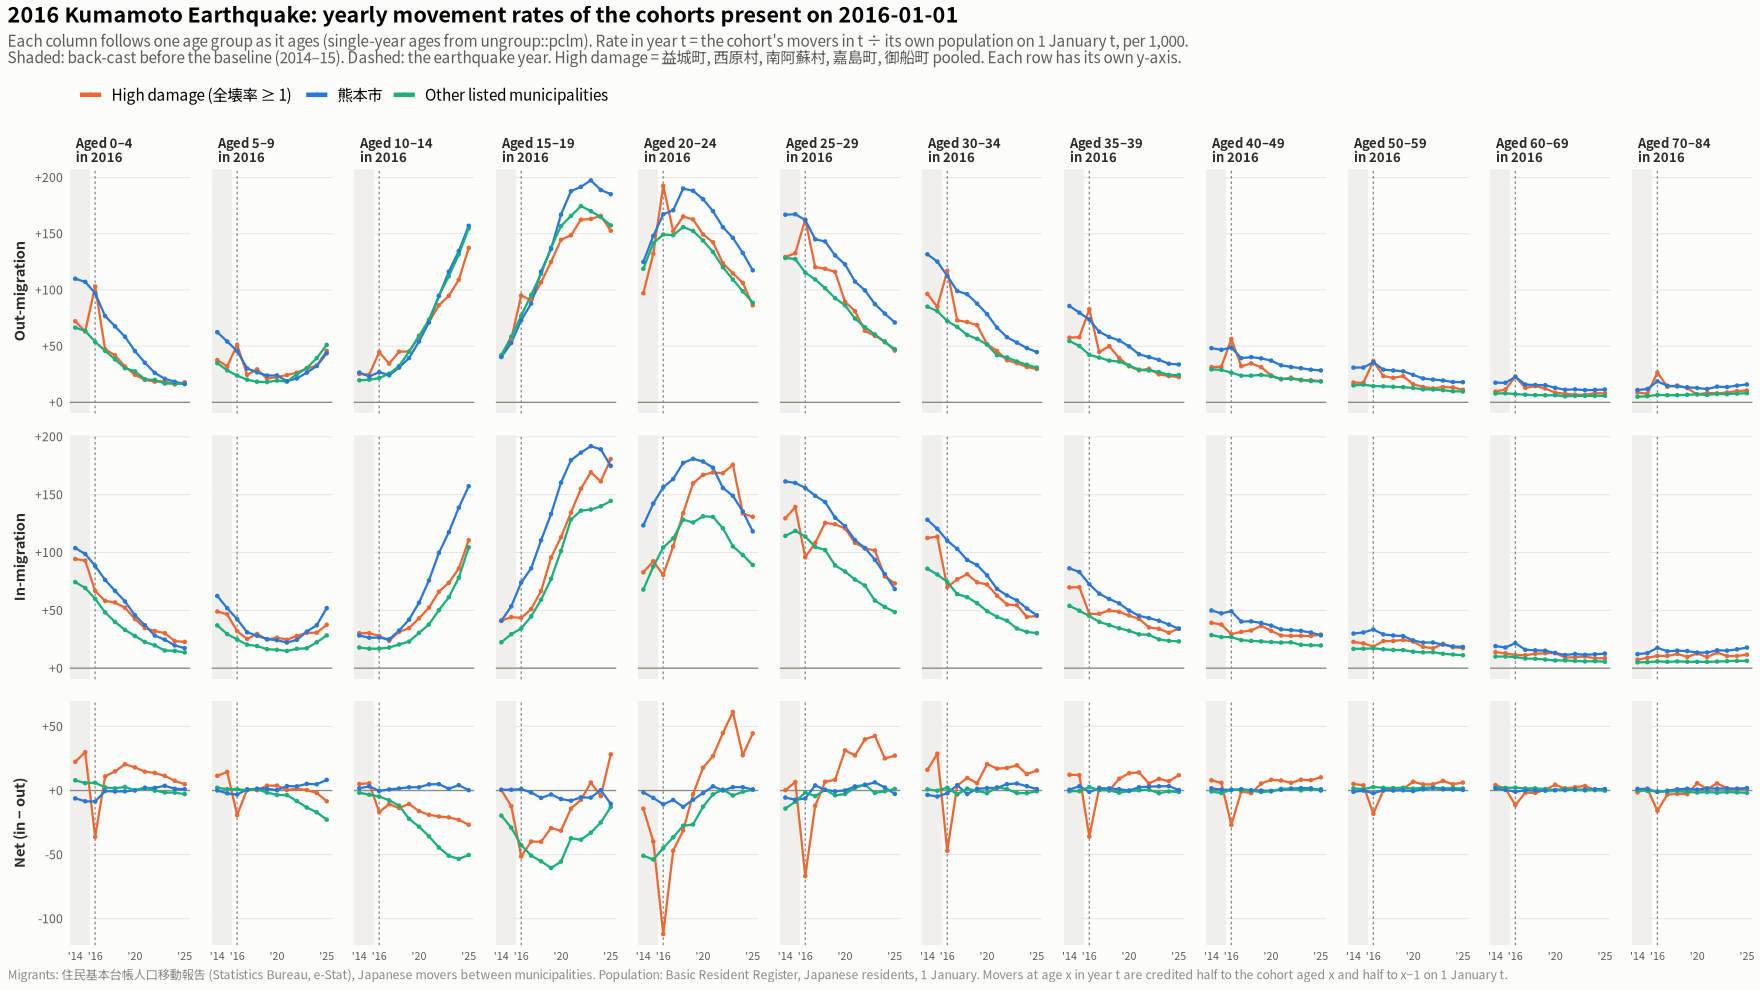

In [12]:
cr_long <- cr_group |>
  pivot_longer(c(`Out-migration`, `In-migration`, `Net (in − out)`), names_to = "measure", values_to = "rate") |>
  mutate(measure = factor(measure, levels = c("Out-migration", "In-migration", "Net (in − out)")),
         cohort_lab = factor(paste0("Aged ", cohort, "\nin 2016"), levels = paste0("Aged ", cohort_bins, "\nin 2016")))

p4 <- ggplot(cr_long, aes(year, rate, colour = group)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = event_x, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(linewidth = 0.7) +
  geom_point(size = 0.8) +
  facet_grid(measure ~ cohort_lab, scales = "free_y", switch = "y") +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_x_continuous(breaks = c(2014, 2016, 2020, 2025), labels = c("'14", "'16", "'20", "'25")) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: yearly movement rates of the cohorts present on 2016-01-01",
       subtitle = paste0("Each column follows one age group as it ages (single-year ages from ungroup::pclm). Rate in year t = the cohort's movers in t ÷ its own population on 1 January t, ",
                         "per 1,000.\nShaded: back-cast before the baseline (2014–15). Dashed: the earthquake year. ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled. Each row has its own y-axis."),
       x = NULL, y = NULL,
       caption = paste0(src_note, " Movers at age x in year t are credited half to the cohort aged x and half to x−1 on 1 January t.")) +
  base_theme() +
  theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 90, hjust = 0.5),
        strip.text.x = element_text(size = 8.5), axis.text.x = element_text(size = 7)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p4, "04_cohort_rates_groups", width = 20, height = 10)

### Net cohort rates per municipality (figures 5–7)

The same net rate (in − out per 1,000), cohort × year, for **all 45 listed municipalities**, with the original 5-year cohorts.

- **Layout:** 15 municipalities per figure, ordered by 全壊率, highest first.
- **Panel titles:** 全壊率 and the population on 2016-01-01 (Japanese residents, the denominator basis used here).
- **Colour:** orange = net loss, blue = net gain, grey ≈ 0. The scale is capped at ±60 per 1,000, so the darkest cells may be larger.
- **Small municipalities:** in the smallest villages a cohort can be a few dozen people and the single-year split is a smooth guess (see figures 1–2), so single cells are noisy. Read the broad patterns only.
- **Other disasters:** the July 2020 Kyushu floods (令和2年7月豪雨) hit the Kuma river basin (球磨村, 人吉市, 芦北町, 八代市 among the listed municipalities). The broad losses in 球磨村 from 2020 are from the floods, not the earthquake.

In [13]:
pop_base <- pop5 |> filter(year == base_year, age_band == "total") |> select(code, pop_2016 = n)

coh5 <- coh1 |>
  filter(a0 <= 84) |>
  mutate(cohort = factor(paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                         levels = paste0(seq(0, 80, 5), "–", seq(4, 84, 5)))) |>
  group_by(code, short, cohort, year) |>
  summarise(net = 1000 * (sum(`in`) - sum(out)) / sum(P), .groups = "drop")

# Panel order and labels: 全壊率 (highest first), then population
panel_tbl <- study |>
  left_join(pop_base, by = "code") |>
  arrange(desc(zenkai_rate), desc(pop_2016)) |>
  mutate(rank = row_number(),
         figure = (rank - 1) %/% 15 + 1,
         label = sprintf("%s\n全壊率 %.2f · pop. %s", short, zenkai_rate, scales::comma(pop_2016)))
coh5 <- coh5 |>
  left_join(panel_tbl |> select(code, rank, figure, label), by = "code") |>
  mutate(label = factor(label, levels = panel_tbl$label))

panel_tbl |> select(figure, rank, municipality = short, `全壊率` = zenkai_rate, pop_2016) |>
  mutate(`全壊率` = round(`全壊率`, 2)) |> as.data.frame()

figure,rank,municipality,全壊率,pop_2016
<dbl>,<int>,<chr>,<dbl>,<dbl>
1,1,益城町,8.75,34503
1,2,西原村,7.25,7037
1,3,南阿蘇村,5.98,11649
1,4,嘉島町,2.54,9196
1,5,御船町,2.51,17665
1,6,甲佐町,0.94,11082
1,7,宇城市,0.89,60634
1,8,産山村,0.75,1566
1,9,大津町,0.45,33904


In [14]:
cap <- 60
plot_net_heat <- function(k) {
  dd <- coh5 |> filter(figure == k)
  ranks <- range(dd$rank)
  ggplot(dd, aes(year, cohort, fill = pmax(pmin(net, cap), -cap))) +
    geom_tile(colour = surface, linewidth = 0.3) +
    geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
    facet_wrap(~label, ncol = 5) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap, cap), breaks = seq(-cap, cap, 20),
                         labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = "Net per 1,000") +
    scale_x_continuous(breaks = c(2014, 2016, 2020, 2025), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0), labels = function(l) ifelse(seq_along(l) %% 2 == 1, l, "")) +
    labs(title = sprintf("Net migration rate of each 2016-01-01 cohort, by year: listed Kumamoto municipalities %d–%d of 45 (by 全壊率)",
                         ranks[1], ranks[2]),
         subtitle = paste0("Rows: age group on 2016-01-01, followed as it ages. Columns: calendar year (2014–15 back-cast). ",
                           "Net = (in − out) movers in the year ÷ the cohort's 1 January population, per 1,000.\n",
                           "Panel titles: 全壊率 (fully destroyed buildings per 100 residents) and population on 2016-01-01 (Japanese residents). ",
                           "Dashed line: start of the earthquake year 2016. Small municipalities are noisy; read broad patterns only."),
         x = NULL, y = "Age on 2016-01-01", caption = src_note) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right",
          legend.justification = "center", legend.key.height = unit(1.4, "cm"),
          strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9, lineheight = 1.1),
          axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7))
}

### Figure 5: municipalities 1–15 by 全壊率

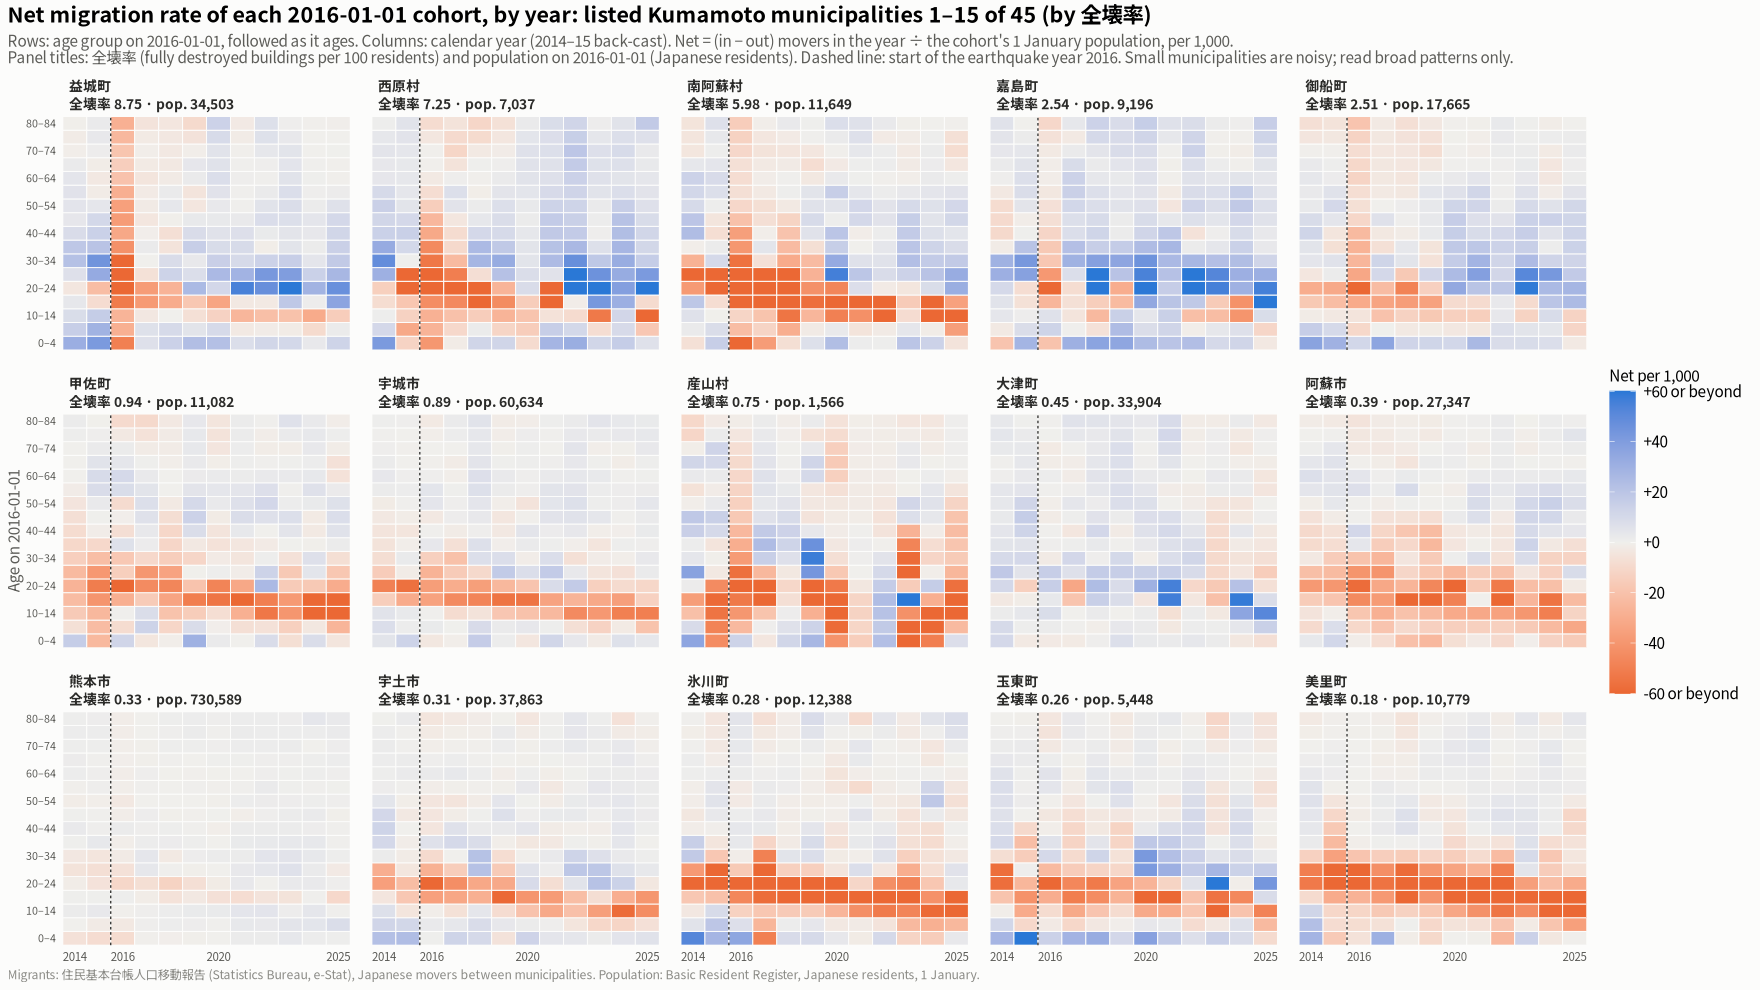

In [15]:
show_save(plot_net_heat(1), "05_cohort_net_rate_1", width = 18, height = 12)

### Figure 6: municipalities 16–30 by 全壊率

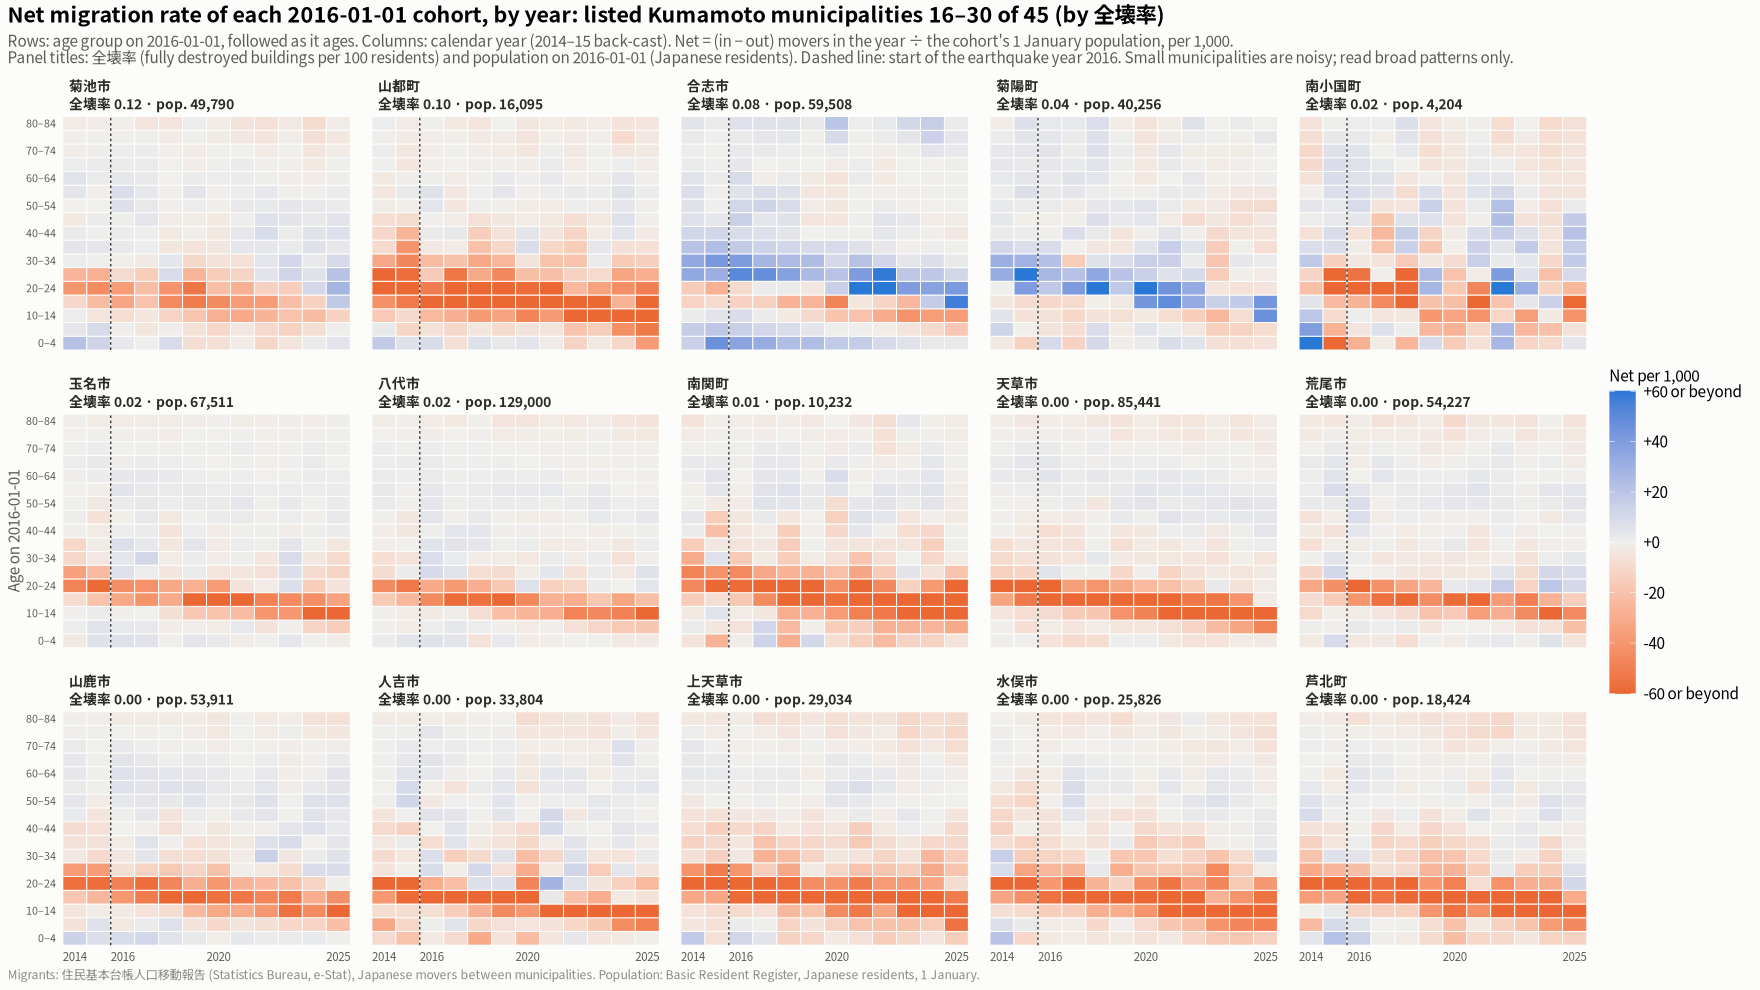

In [16]:
show_save(plot_net_heat(2), "06_cohort_net_rate_2", width = 18, height = 12)

### Figure 7: municipalities 31–45 by 全壊率

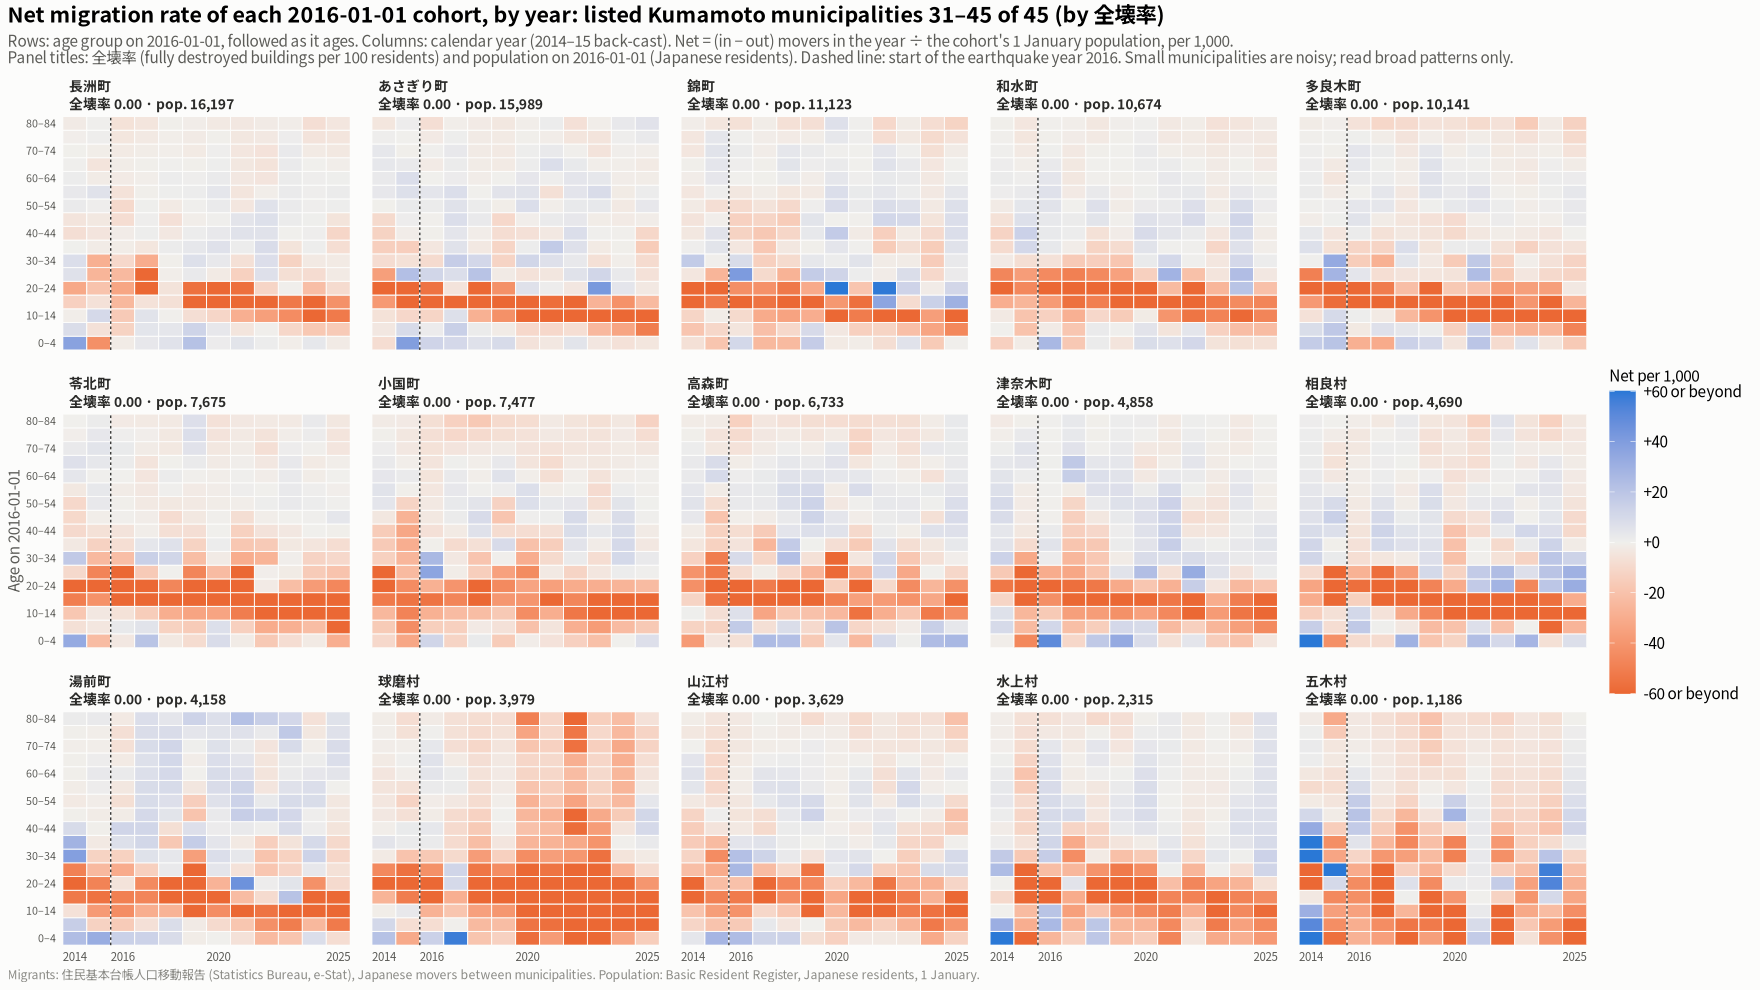

In [17]:
show_save(plot_net_heat(3), "07_cohort_net_rate_3", width = 18, height = 12)

## 5. Change in net migration from the pre-quake baseline, by age band

The published 5-year bands, as in section 3 (no ungrouping; top band 80+). For group *g*, band *b* and calendar year *t*:

- **Net rate:** rate(*g*, *b*, *t*) = 1000 · (Σ in − Σ out) ÷ Σ 1 January population, pooled over the group's municipalities.
- **Baseline:** base(*g*, *b*) is the mean of the band's 2014 and 2015 net rates: (rate<sub>2014</sub> + rate<sub>2015</sub>) / 2.
- **Change** = rate − base, in points per 1,000 per year. Negative (orange) means the band lost more, or gained less, than before the quake.

The 2014 and 2015 cells are shown too. By construction they are equal and opposite (±half the 2014–15 difference), so their spread is a rough guide to year-to-year noise. Groups are those of sections 3–4. In "Other listed", changes from 2020 include the July 2020 Kuma river floods (球磨村, 人吉市, 芦北町, 八代市).


In [18]:
yr5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  left_join(study |> select(code, group), by = "code") |>
  group_by(group, band, year) |>
  summarise(pop = sum(pop), net = sum(`in`) - sum(out), .groups = "drop")
base5 <- yr5 |>
  filter(year <= 2015) |>
  group_by(group, band) |>
  summarise(base = mean(1000 * net / pop), .groups = "drop")   # mean of the 2014 and 2015 rates
chg5 <- yr5 |>
  left_join(base5, by = c("group", "band")) |>
  mutate(rate = 1000 * net / pop, change = rate - base,
         group = factor(group, levels = group_levels),
         band = factor(band, levels = bands5))

# Table: change from baseline (per 1,000), high-damage group, young adult bands
chg5 |>
  filter(group == group_levels[1], band %in% c("15_19", "20_24", "25_29", "30_34", "35_39")) |>
  mutate(change = round(change, 1)) |>
  select(band, year, change) |>
  pivot_wider(names_from = year, values_from = change) |>
  left_join(base5 |> filter(group == group_levels[1]) |> transmute(band, baseline = round(base, 1)), by = "band") |>
  as.data.frame()


band,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,baseline
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
15_19,6.9,-6.9,-33.0,-18.6,-20.3,-10.9,-15.6,-10.6,-7.3,-4.2,3.3,-4.3,-11.7
20_24,10.0,-10.0,-84.0,-21.8,-12.3,2.9,3.9,13.5,15.6,10.2,-2.6,0.7,-32.4
25_29,-1.4,1.4,-81.3,-40.6,-26.5,-8.2,7.3,13.0,16.5,35.3,3.2,31.4,18.3
30_34,-7.5,7.5,-69.8,-17.6,-9.0,-13.8,8.5,6.3,25.5,30.1,5.4,15.1,20.0
35_39,1.8,-1.8,-46.5,-3.5,-0.1,-3.4,8.5,6.4,14.1,21.8,9.7,18.0,9.9


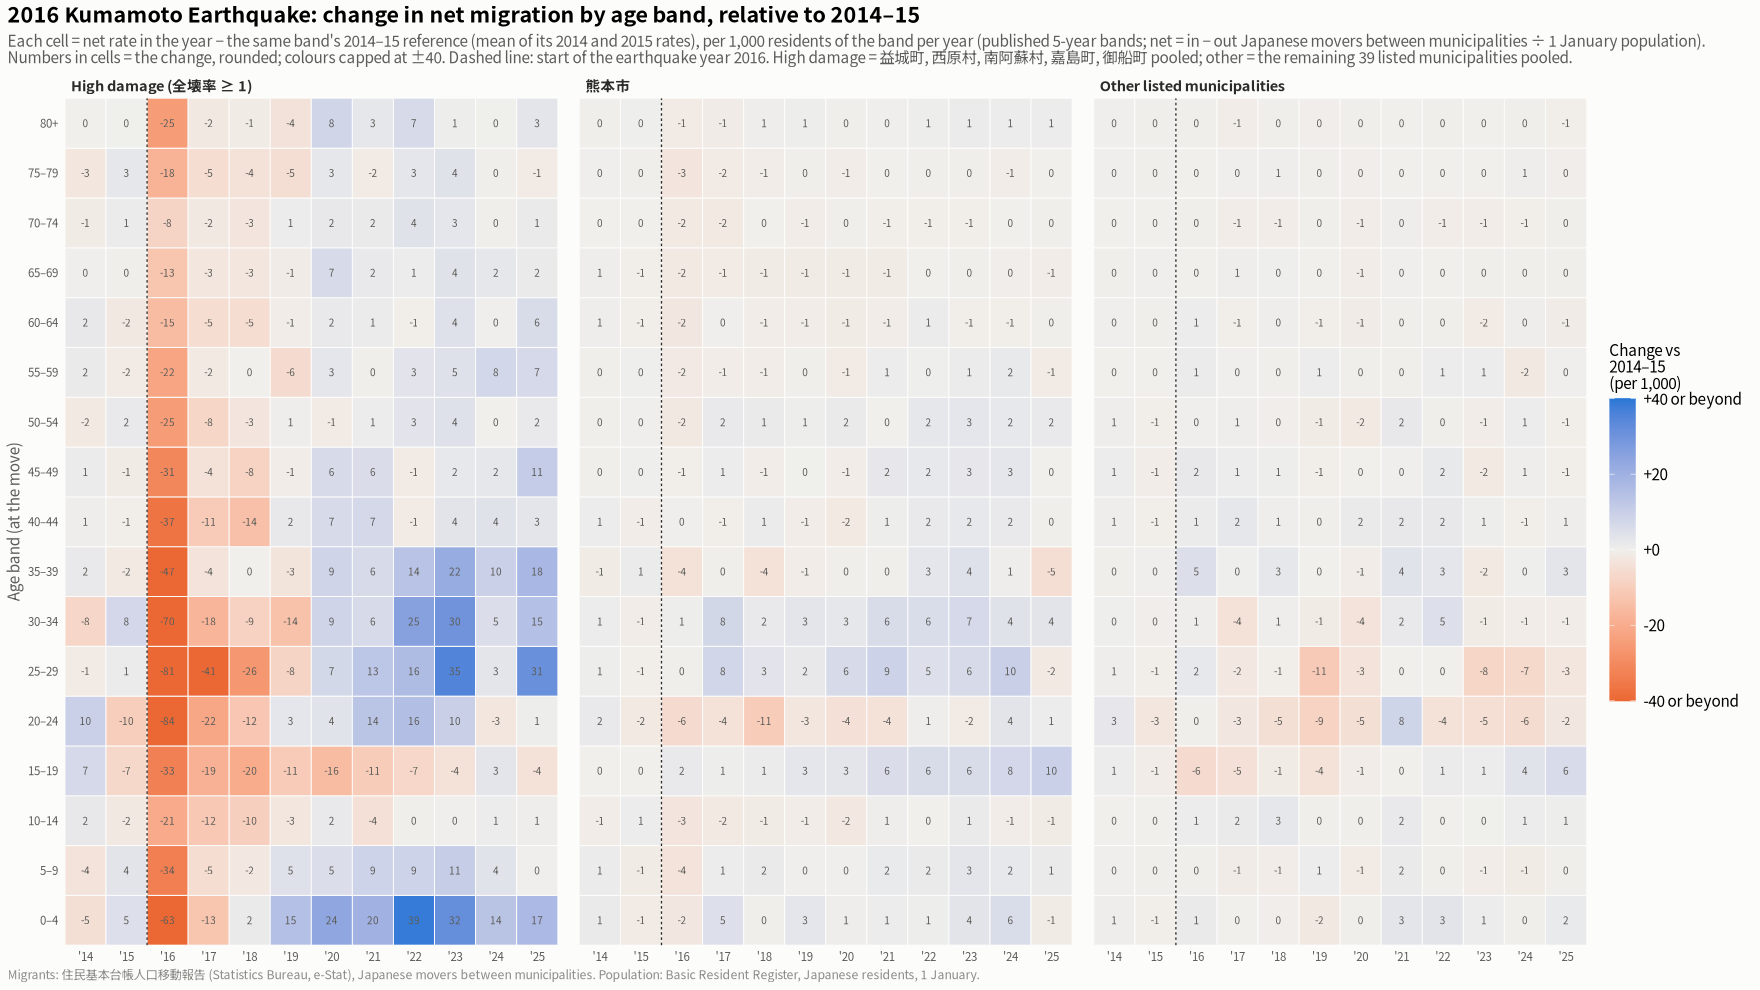

In [19]:
# Diverging fill capped at +-cap; labels mark the capped ends
change_fill <- function(cap, name) {
  scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                       limits = c(-cap, cap), breaks = seq(-cap, cap, cap / 2),
                       labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                       name = name)
}
heat_theme <- function() list(
  base_theme(),
  theme(panel.grid.major.y = element_blank(), legend.position = "right",
        legend.justification = "center", legend.key.height = unit(1.4, "cm"),
        axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7.5))
)

cap8 <- 40
p8 <- ggplot(chg5, aes(year, band, fill = pmax(pmin(change, cap8), -cap8))) +
  geom_tile(colour = surface, linewidth = 0.3) +
  geom_text(aes(label = ifelse(abs(change) < 0.5, "0", sprintf("%.0f", change))), size = 2.3, colour = ink2, family = jp_font) +
  geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
  facet_wrap(~group, nrow = 1) +
  change_fill(cap8, "Change vs\n2014–15\n(per 1,000)") +
  scale_x_continuous(breaks = years, labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
  scale_y_discrete(labels = function(b) sub("_", "–", b), expand = c(0, 0)) +
  labs(title = "2016 Kumamoto Earthquake: change in net migration by age band, relative to 2014–15",
       subtitle = paste0("Each cell = net rate in the year − the same band's 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year (published 5-year bands; ",
                         "net = in − out Japanese movers between municipalities ÷ 1 January population).\n",
                         "Numbers in cells = the change, rounded; colours capped at ±", cap8, ". Dashed line: start of the earthquake year 2016. ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Age band (at the move)", caption = src_note) +
  heat_theme()
show_save(p8, "08_band_change_heat", width = 18, height = 7.5)


### Figure 9: change from baseline per municipality, ages 25–29, 40–44 and 60–64

The same change, for three bands, in **every listed municipality**. Each municipality is compared with **its own** 2014–15 reference for that band: the mean of its 2014 and 2015 net rates.

- **Rows:** municipalities ordered by 全壊率, highest first, within the 3r groups. The label shows 全壊率.
- **Colour:** capped at ±60 per 1,000.
- **Small municipalities:** in the smallest villages a band is a few dozen people, so one or two movers shift a cell by tens per 1,000. The table below gives each band's population on 2016-01-01. Read patterns that persist over years, not single cells.


In [20]:
focus_bands <- c("25_29", "40_44", "60_64")
mun5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  filter(band %in% focus_bands) |>
  mutate(net = `in` - out) |>
  group_by(code, band) |>
  mutate(base = mean(1000 * net[year <= 2015] / pop[year <= 2015]),   # mean of the 2014 and 2015 rates
         change = 1000 * net / pop - base) |>
  ungroup() |>
  left_join(panel_tbl |> select(code, short, zenkai_rate, rank), by = "code") |>
  left_join(study |> select(code, group), by = "code") |>
  mutate(group = factor(group, levels = group_levels),
         band = factor(sub("_", "–", band), levels = sub("_", "–", focus_bands)))
row_lab <- panel_tbl |> arrange(rank) |> mutate(lab = sprintf("%s  %.2f", short, zenkai_rate))
mun5 <- mun5 |> mutate(row = factor(sprintf("%s  %.2f", short, zenkai_rate), levels = rev(row_lab$lab)))

# Table: band population on 2016-01-01 and the 2014-15 baseline net rate, per municipality
mun5 |>
  filter(year == base_year) |>
  select(rank, municipality = short, `全壊率` = zenkai_rate, band, pop) |>
  left_join(mun5 |> distinct(short, band, base) |> rename(municipality = short), by = c("municipality", "band")) |>
  mutate(`全壊率` = round(`全壊率`, 2), base = round(base, 1)) |>
  pivot_wider(names_from = band, values_from = c(pop, base)) |>
  arrange(rank) |>
  as.data.frame()


rank,municipality,全壊率,pop_25–29,pop_40–44,pop_60–64,base_25–29,base_40–44,base_60–64
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,益城町,8.75,1710,2268,2572,30.9,11.3,3.6
2,西原村,7.25,326,471,596,2.2,6.3,-1.6
3,南阿蘇村,5.98,378,668,1068,-32.3,10.9,10.4
4,嘉島町,2.54,478,606,610,48.9,-6.7,1.9
5,御船町,2.51,776,1024,1510,6.8,9.6,2.7
6,甲佐町,0.94,396,600,897,-32.6,-0.1,4.3
7,宇城市,0.89,2736,3514,4822,-5.1,-6.0,2.1
8,産山村,0.75,51,57,134,-37.4,42.4,10.8
9,大津町,0.45,2148,2380,2109,7.1,12.7,0.5


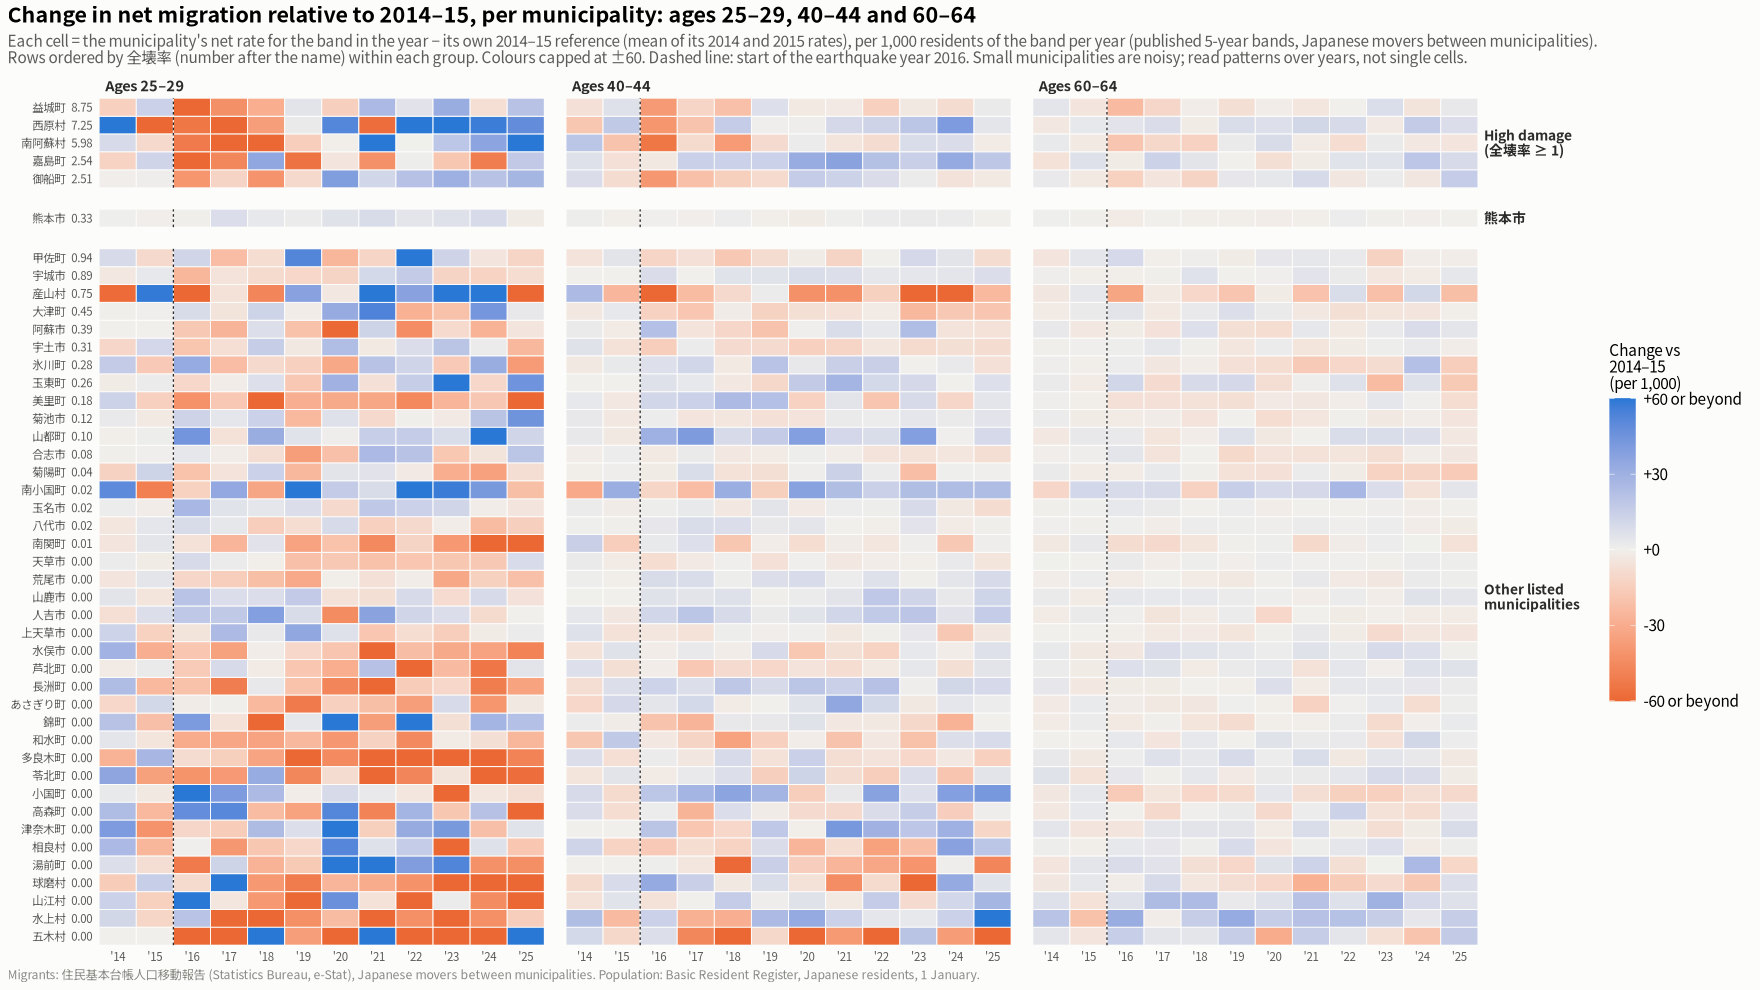

In [21]:
cap9 <- 60
p9 <- ggplot(mun5, aes(year, row, fill = pmax(pmin(change, cap9), -cap9))) +
  geom_tile(colour = surface, linewidth = 0.3) +
  geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
  facet_grid(group ~ band, scales = "free_y", space = "free_y",
             labeller = labeller(band = function(b) paste0("Ages ", b), group = label_wrap_gen(14))) +
  change_fill(cap9, "Change vs\n2014–15\n(per 1,000)") +
  scale_x_continuous(breaks = years, labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
  scale_y_discrete(expand = c(0, 0)) +
  labs(title = "Change in net migration relative to 2014–15, per municipality: ages 25–29, 40–44 and 60–64",
       subtitle = paste0("Each cell = the municipality's net rate for the band in the year − its own 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year ",
                         "(published 5-year bands, Japanese movers between municipalities).\n",
                         "Rows ordered by 全壊率 (number after the name) within each group. Colours capped at ±", cap9, ". ",
                         "Dashed line: start of the earthquake year 2016. Small municipalities are noisy; read patterns over years, not single cells."),
       x = NULL, y = NULL, caption = src_note) +
  heat_theme() +
  theme(strip.text.y = element_text(angle = 0, hjust = 0, size = 9))
show_save(p9, "09_band_change_by_muni", width = 16, height = 15)


### Figure 10: figure 8 as line plots, one panel per group

The same changes as figure 8 (`chg5`), with one panel per group (high damage, 熊本市, other listed) and one line per 5-year age band. Colour shows the life stage (green 0–14, orange/red 15–39, blue 40–64, purple 65+); shade and line type tell the bands within a stage apart. All three panels share one y-axis, so the size of the changes can be compared directly between groups. The grey area marks the 2014–15 baseline years; the dashed line marks the earthquake year 2016.


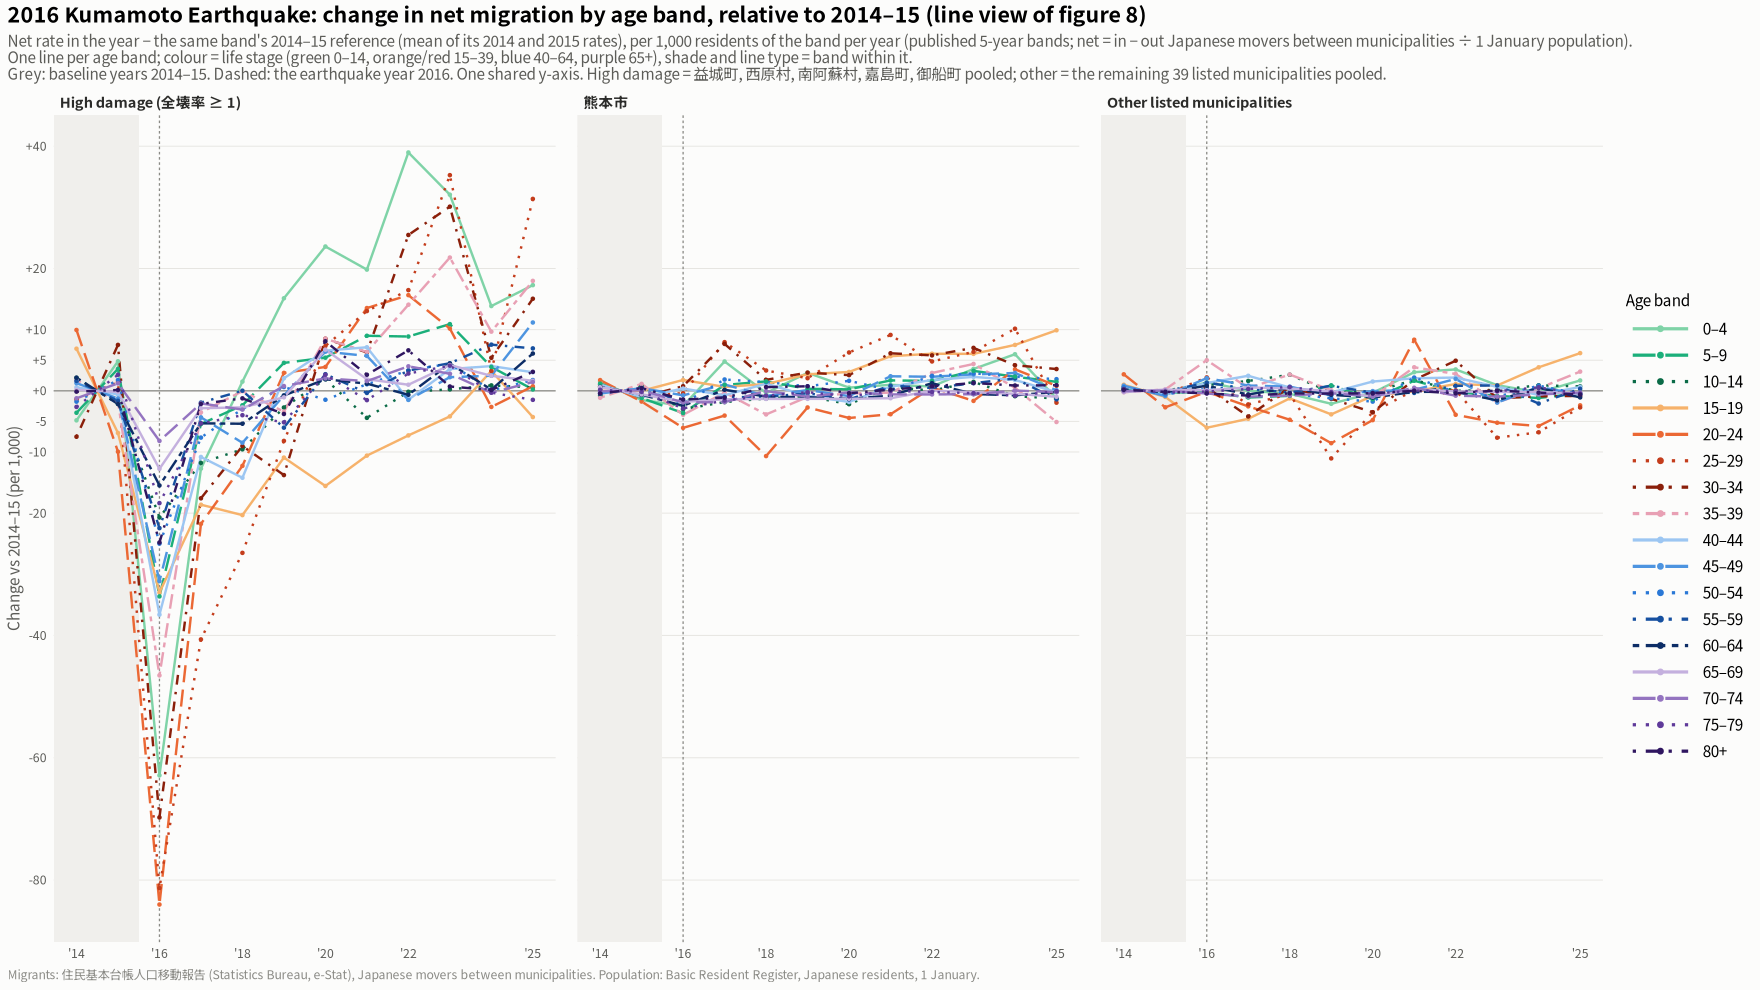

In [22]:
# Colour = life stage (hue family), shade + line type = band within it
band_family <- list(
  `0–14`  = c("#7fd3a7", "#1baf7a", "#0b6b47"),                          # greens
  `15–39` = c("#f6b26b", "#eb6834", "#c43d1c", "#8a1f0a", "#e8a0b4"),    # oranges / reds
  `40–64` = c("#9cc6f2", "#4d94e0", "#2a78d6", "#1650a0", "#0d2d66"),    # blues
  `65+`   = c("#c4b0de", "#9474c0", "#5f3a9a", "#2f1660"))              # purples
band_cols <- setNames(unlist(band_family, use.names = FALSE), bands5)
lty_seq <- c("solid", "longdash", "dotted", "dotdash", "twodash")
band_lty <- setNames(unlist(lapply(band_family, function(f) lty_seq[seq_along(f)]), use.names = FALSE), bands5)
p10 <- ggplot(chg5, aes(year, change, colour = band, linetype = band, group = band)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = event_x, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(linewidth = 0.75) +
  geom_point(size = 0.8) +
  facet_wrap(~group, nrow = 1) +
  scale_colour_manual(values = band_cols, labels = function(b) sub("_", "–", b), name = "Age band") +
  scale_linetype_manual(values = band_lty, labels = function(b) sub("_", "–", b), name = "Age band") +
  scale_x_continuous(breaks = c(2014, 2016, 2018, 2020, 2022, 2025), labels = function(v) paste0("'", substr(v, 3, 4))) +
  scale_y_continuous(breaks = sort(unique(c(seq(-100, 100, 20), -10, -5, 5, 10))), labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: change in net migration by age band, relative to 2014–15 (line view of figure 8)",
       subtitle = paste0("Net rate in the year − the same band's 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year (published 5-year bands; ",
                         "net = in − out Japanese movers between municipalities ÷ 1 January population).\n",
                         "One line per age band; colour = life stage (green 0–14, orange/red 15–39, blue 40–64, purple 65+), shade and line type = band within it.\nGrey: baseline years 2014–15. Dashed: the earthquake year 2016. ",
                         "One shared y-axis. High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Change vs 2014–15 (per 1,000)", caption = src_note) +
  base_theme() +
  theme(legend.position = "right", legend.justification = "center") +
  guides(colour = guide_legend(ncol = 1, override.aes = list(linewidth = 1, size = 1.5)),
         linetype = guide_legend(ncol = 1)) +
  theme(legend.key.width = unit(1.6, "cm"))
show_save(p10, "10_band_change_lines", width = 18, height = 7)
